# Suicide Rates Overview 1985-2016: Data Cleaning, Visualization & Insights

**Name:** PATEL KRISH SHAILESHBHAI

**Enrollment No.:** IU2441230678  
**Team:** TITANS  
**Dataset:** [Suicide Rates Overview 1985 to 2016 (Kaggle)](https://www.kaggle.com/datasets/russellyates88/suicide-rates-overview-1985-to-2016)

**Tasks:** (1) Data cleaning: missing values, duplicates, data types, outliers (2) At least 6 visualizations (3) Short insights report

> How to run: upload `master.csv` to the Colab Files panel (already done), then run all cells. The data cell finds the file automatically.

## 1. Setup and load dataset

In [ ]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os
import zipfile
import urllib.request

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# 1. Unzip existing master.csv.zip if master.csv is not yet extracted
zip_path = "/content/master.csv.zip"
if os.path.exists(zip_path) and not os.path.exists("master.csv"):
    print(f"Found {zip_path}, extracting to current directory...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(".")

# 2. Search for an uploaded or existing CSV locally
cands = glob.glob("/content/**/*.csv", recursive=True) + glob.glob("*.csv")
cands = [p for p in cands if "cleaned" not in os.path.basename(p).lower() and "sample_data" not in p]
cands.sort(key=lambda p: (os.path.basename(p).lower() != "master.csv", len(p)))

if cands:
    path = cands[0]
    print("Found local CSV:", path)
else:
    # 3. Fallback: Download from an active public mirror
    url = "https://raw.githubusercontent.com/joshualand/suicide-rates-overview-1985-to-2016/master/master.csv"
    path = "master.csv"
    print("No local CSV found. Attempting fallback download...")
    try:
        urllib.request.urlretrieve(url, path)
        print("Downloaded successfully to:", path)
    except Exception as e:
        raise FileNotFoundError("Failed to find or download 'master.csv'. Please upload it manually to the left-side panel.") from e

df = pd.read_csv(path)
print("Loaded:", path, "| shape:", df.shape)

Found local CSV: master.csv
Loaded: master.csv | shape: (27820, 12)


## 2. First look at the data

In [ ]:
display(df.head())
df.info()

,country,year,sex,age,suicides_no,population,suicides/100k pop,country-year,HDI for year,gdp_for_year ($),gdp_per_capita ($),generation
0,Albania,1987,male,15-24 years,21,312900,6.71,Albania1987,NaN,"2,156,624,900",796,Generation X
1,Albania,1987,male,35-54 years,16,308000,5.19,Albania1987,NaN,"2,156,624,900",796,Silent
2,Albania,1987,female,15-24 years,14,289700,4.83,Albania1987,NaN,"2,156,624,900",796,Generation X
3,Albania,1987,male,75+ years,1,21800,4.59,Albania1987,NaN,"2,156,624,900",796,G.I. Generation
4,Albania,1987,male,25-34 years,9,274300,3.28,Albania1987,NaN,"2,156,624,900",796,Boomers


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27820 entries, 0 to 27819
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   country             27820 non-null  object 
 1   year                27820 non-null  int64  
 2   sex                 27820 non-null  object 
 3   age                 27820 non-null  object 
 4   suicides_no         27820 non-null  int64  
 5   population          27820 non-null  int64  
 6   suicides/100k pop   27820 non-null  float64
 7   country-year        27820 non-null  object 
 8   HDI for year        8364 non-null   float64
 9    gdp_for_year ($)   27820 non-null  object 
 10  gdp_per_capita ($)  27820 non-null  int64  
 11  generation          27820 non-null  object 
dtypes: float64(2), int64(4), object(6)
memory usage: 2.5+ MB


In [ ]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country,27820,101,Austria,382,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,"27,820.00",NaN,NaN,NaN,"2,001.26",8.47,"1,985.00","1,995.00","2,002.00","2,008.00","2,016.00"
sex,27820,2,male,13910,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,27820,6,15-24 years,4642,NaN,NaN,NaN,NaN,NaN,NaN,NaN
suicides_no,"27,820.00",NaN,NaN,NaN,242.57,902.05,0.00,3.00,25.00,131.00,"22,338.00"
population,"27,820.00",NaN,NaN,NaN,"1,844,793.62","3,911,779.44",278.00,"97,498.50","430,150.00","1,486,143.25","43,805,214.00"
suicides/100k pop,"27,820.00",NaN,NaN,NaN,12.82,18.96,0.00,0.92,5.99,16.62,224.97
country-year,27820,2321,Uzbekistan2014,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HDI for year,"8,364.00",NaN,NaN,NaN,0.78,0.09,0.48,0.71,0.78,0.85,0.94
gdp_for_year ($),27820,2321,"63,067,077,179",12,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data cleaning

### 3.1 Standardize column names
The raw file has awkward names (spaces, `$`, `/`, leading/trailing spaces such as `" gdp_for_year ($) "`).

In [ ]:
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
df = df.rename(columns={"suicides_100k_pop": "suicides_per_100k"})
print(list(df.columns))

['country', 'year', 'sex', 'age', 'suicides_no', 'population', 'suicides_per_100k', 'country_year', 'hdi_for_year', 'gdp_for_year', 'gdp_per_capita', 'generation']


### 3.2 Missing values

,missing,percent
hdi_for_year,19456,69.94
country,0,0.00
sex,0,0.00
year,0,0.00
age,0,0.00
suicides_no,0,0.00
suicides_per_100k,0,0.00
population,0,0.00
country_year,0,0.00
gdp_for_year,0,0.00


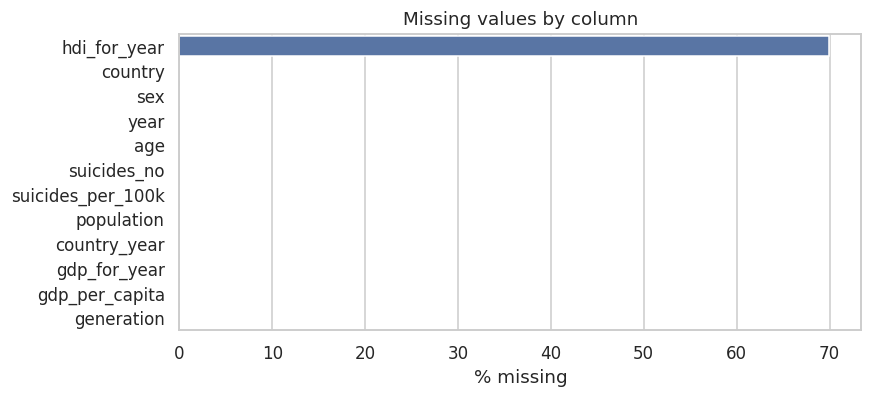

In [ ]:
miss = pd.DataFrame({"missing": df.isna().sum(),
                     "percent": df.isna().mean() * 100}).sort_values("percent", ascending=False)
display(miss)

plt.figure(figsize=(8, 3.5))
sns.barplot(x=miss["percent"], y=miss.index, color="#4c72b0")
plt.xlabel("% missing"); plt.ylabel(""); plt.title("Missing values by column")
plt.show()

`hdi_for_year` is missing for roughly 70% of rows. Imputing that much data would fabricate values, so the column is
**dropped**. All other columns are complete.

In [ ]:
df = df.drop(columns=["hdi_for_year"])
print("Remaining missing values:", int(df.isna().sum().sum()))

Remaining missing values: 0


### 3.3 Duplicates

In [ ]:
print("Fully duplicated rows:", df.duplicated().sum())
key = ["country", "year", "sex", "age"]
print("Duplicate (country, year, sex, age) keys:", df.duplicated(subset=key).sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after de-duplication:", df.shape)

Fully duplicated rows: 0
Duplicate (country, year, sex, age) keys: 0
Shape after de-duplication: (27820, 11)


### 3.4 Data types
`gdp_for_year` is stored as text with thousands separators (e.g. `"2,156,624,900"`). Convert it to numeric,
and make `age`, `sex`, `generation`, `country` proper categoricals (age gets a logical order).

In [ ]:
df["gdp_for_year"] = pd.to_numeric(df["gdp_for_year"].astype(str).str.replace(",", "", regex=False).str.strip(),
                                   errors="coerce")

age_order = ["5-14 years", "15-24 years", "25-34 years", "35-54 years", "55-74 years", "75+ years"]
gen_order = ["G.I. Generation", "Silent", "Boomers", "Generation X", "Millenials", "Generation Z"]

df["age"] = pd.Categorical(df["age"].str.strip(), categories=age_order, ordered=True)
df["generation"] = pd.Categorical(df["generation"].str.strip(), categories=gen_order, ordered=True)
df["sex"] = df["sex"].str.strip().astype("category")
df["country"] = df["country"].str.strip().astype("category")
df["year"] = df["year"].astype("int16")

print(df.dtypes)
print("Unparseable GDP values:", df["gdp_for_year"].isna().sum())

country              category
year                    int16
sex                  category
age                  category
suicides_no             int64
population              int64
suicides_per_100k     float64
country_year           object
gdp_for_year            int64
gdp_per_capita          int64
generation           category
dtype: object
Unparseable GDP values: 0


### 3.5 Consistency checks
Check that the rate column is consistent with `suicides_no / population * 100000`, look for impossible values, and check
year coverage (2016 is known to be sparse in this dataset).

In [ ]:
calc = df["suicides_no"] / df["population"] * 100_000
print("Max abs. difference vs recomputed rate:", round((calc - df["suicides_per_100k"]).abs().max(), 3))
print("Negative values:", int((df[["suicides_no", "population", "suicides_per_100k", "gdp_per_capita"]] < 0).sum().sum()))
print("Zero population rows:", int((df["population"] == 0).sum()))

cov = df.groupby("year")["country"].nunique()
display(cov.tail(6).to_frame("countries reporting"))

Max abs. difference vs recomputed rate: 0.005
Negative values: 0
Zero population rows: 0


,countries reporting
year,
2011,86
2012,81
2013,80
2014,78
2015,62
2016,16


2016 has far fewer countries than other years, so including it would distort trends. It is **excluded** from the analysis.

In [ ]:
df = df[df["year"] <= 2015].copy()
print("Years:", df["year"].min(), "-", df["year"].max(), "| rows:", len(df), "| countries:", df["country"].nunique())

Years: 1985 - 2015 | rows: 27660 | countries: 100


### 3.6 Outliers (IQR method)

IQR bounds: [-22.63, 40.14]  -> 2040 outliers (7.4% of rows)


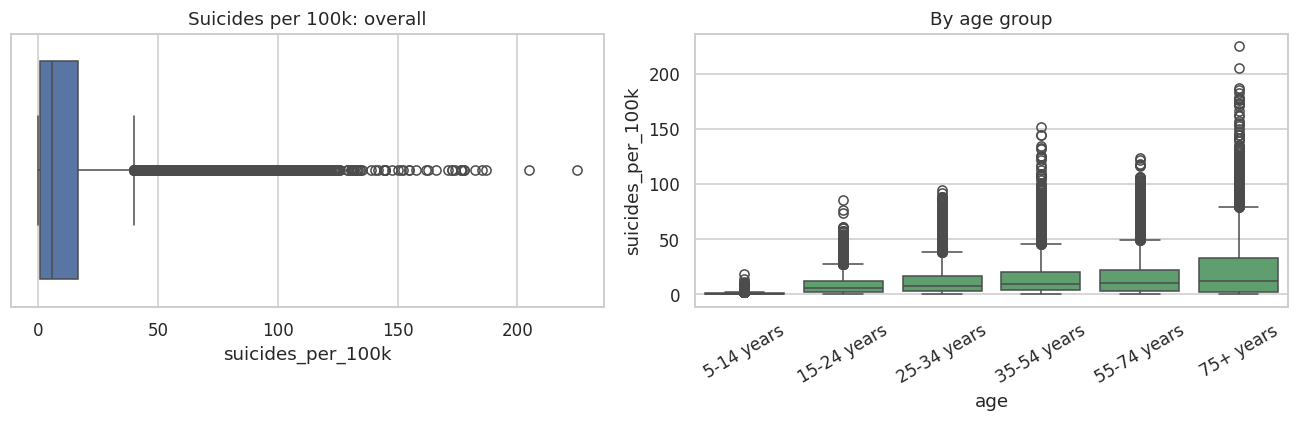

Outlier share by group:


age,15-24 years,25-34 years,35-54 years,55-74 years,75+ years
sex,,,,,
female,2,0,0,1,68
male,78,225,342,444,880


Countries with most outlier rows:


,count
country,
Russian Federation,122
Kazakhstan,116
Ukraine,103
Lithuania,101
Hungary,88
Belarus,83
Latvia,76
Finland,75


In [ ]:
col = "suicides_per_100k"
q1, q3 = df[col].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out = df[(df[col] < low) | (df[col] > high)]
print(f"IQR bounds: [{low:.2f}, {high:.2f}]  -> {len(out)} outliers ({len(out)/len(df)*100:.1f}% of rows)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df[col], ax=ax[0], color="#4c72b0"); ax[0].set_title("Suicides per 100k: overall")
sns.boxplot(data=df, x="age", y=col, ax=ax[1], color="#55a868")
ax[1].set_title("By age group"); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

print("Outlier share by group:")
display(out.groupby(["sex", "age"], observed=True).size().unstack().fillna(0).astype(int))
print("Countries with most outlier rows:")
display(out["country"].value_counts().head(8))

**Decision:** the outliers are concentrated in older male groups and a handful of countries. They are real observations (not
errors), so they are **kept** rather than deleted. For plots and summaries, group-level aggregates (population-weighted rates and medians)
are used so that single extreme rows do not dominate.

In [ ]:
# Helper: population-weighted rate for any grouping (more correct than averaging the per-row rates)
def rate(data, by):
    g = data.groupby(by, observed=True)[["suicides_no", "population"]].sum()
    g["rate"] = g["suicides_no"] / g["population"] * 100_000
    return g

print("Cleaned dataset:", df.shape)
display(df.head())
df.to_csv("suicide_rates_cleaned.csv", index=False)   # downloadable from the Colab file panel

Cleaned dataset: (27660, 11)


,country,year,sex,age,suicides_no,population,suicides_per_100k,country_year,gdp_for_year,gdp_per_capita,generation
0,Albania,1987,male,15-24 years,21,312900,6.71,Albania1987,2156624900,796,Generation X
1,Albania,1987,male,35-54 years,16,308000,5.19,Albania1987,2156624900,796,Silent
2,Albania,1987,female,15-24 years,14,289700,4.83,Albania1987,2156624900,796,Generation X
3,Albania,1987,male,75+ years,1,21800,4.59,Albania1987,2156624900,796,G.I. Generation
4,Albania,1987,male,25-34 years,9,274300,3.28,Albania1987,2156624900,796,Boomers


## 4. Visualizations

### 4.1 Global suicide rate over time

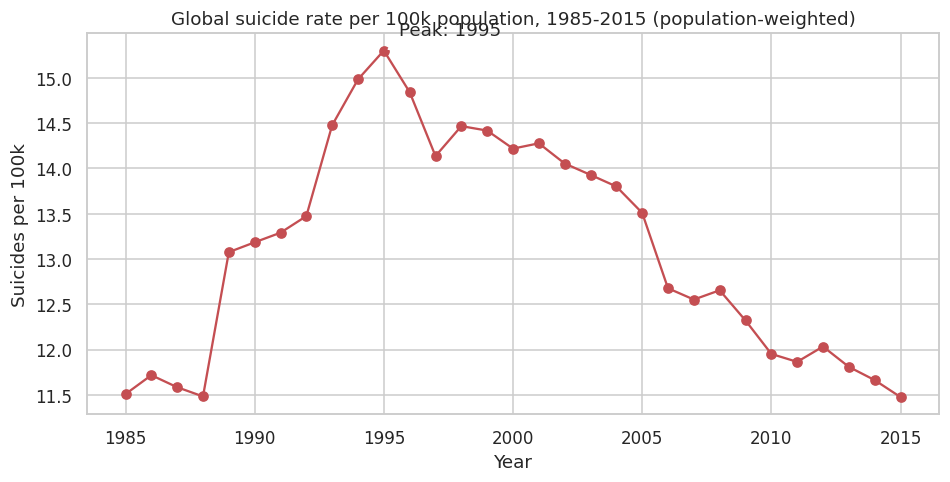

In [ ]:
t = rate(df, "year").reset_index()
plt.figure(figsize=(10, 4.5))
plt.plot(t["year"], t["rate"], marker="o", color="#c44e52")
plt.title("Global suicide rate per 100k population, 1985-2015 (population-weighted)")
plt.xlabel("Year"); plt.ylabel("Suicides per 100k")
peak = t.loc[t["rate"].idxmax()]
plt.annotate(f"Peak: {peak['year']:.0f}", (peak["year"], peak["rate"]),
             xytext=(10, 10), textcoords="offset points", arrowprops=dict(arrowstyle="->"))
plt.show()

### 4.2 Trend by sex

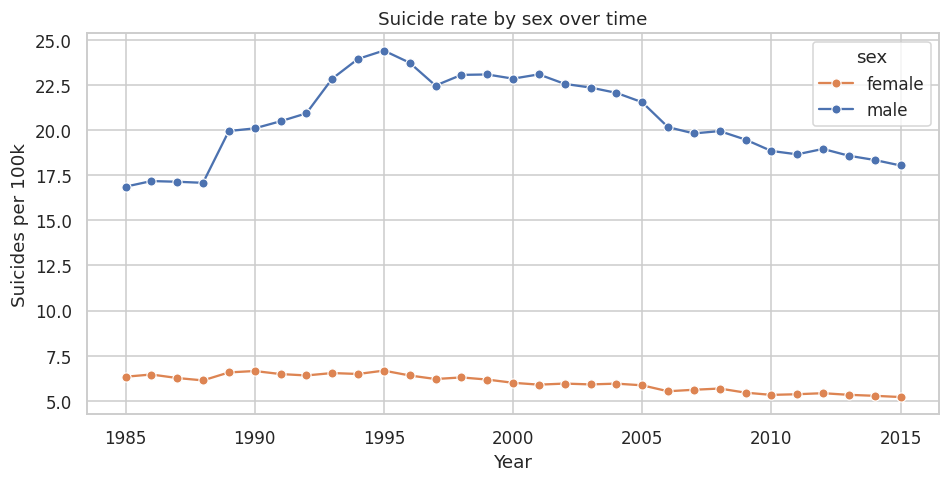

In [ ]:
ts = rate(df, ["year", "sex"]).reset_index()
plt.figure(figsize=(10, 4.5))
sns.lineplot(data=ts, x="year", y="rate", hue="sex", marker="o", palette={"male": "#4c72b0", "female": "#dd8452"})
plt.title("Suicide rate by sex over time"); plt.xlabel("Year"); plt.ylabel("Suicides per 100k")
plt.show()

### 4.3 Rate by age group and sex

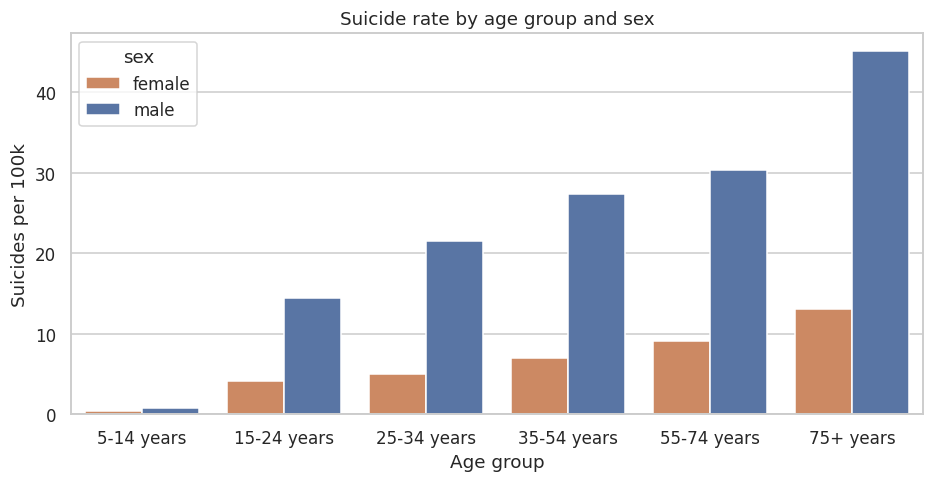

In [ ]:
ta = rate(df, ["age", "sex"]).reset_index()
plt.figure(figsize=(10, 4.5))
sns.barplot(data=ta, x="age", y="rate", hue="sex", palette={"male": "#4c72b0", "female": "#dd8452"})
plt.title("Suicide rate by age group and sex"); plt.xlabel("Age group"); plt.ylabel("Suicides per 100k")
plt.show()

### 4.4 Top 10 countries by overall rate

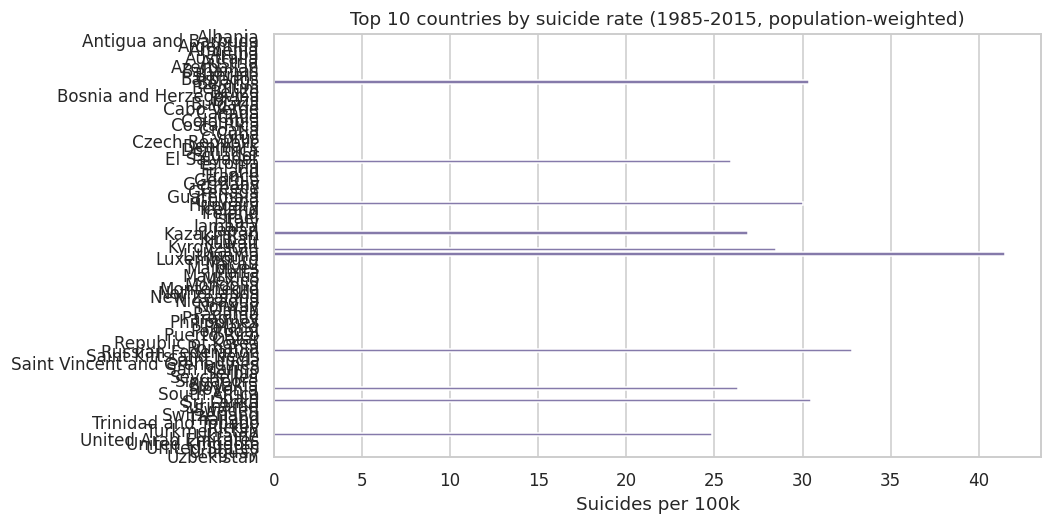

In [ ]:
tc = rate(df, "country")
tc = tc[tc["population"] > 0].sort_values("rate", ascending=False).head(10).reset_index()
plt.figure(figsize=(9, 5))
sns.barplot(data=tc, y="country", x="rate", color="#8172b2")
plt.title("Top 10 countries by suicide rate (1985-2015, population-weighted)")
plt.xlabel("Suicides per 100k"); plt.ylabel("")
plt.show()

### 4.5 Generation comparison

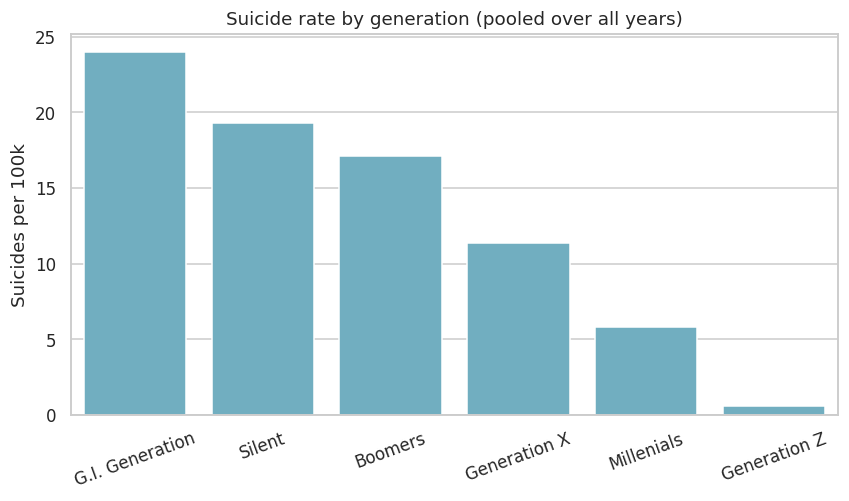

Note: generations span different ages/years, so this pools different life stages.


In [ ]:
tg = rate(df, "generation").reset_index()
plt.figure(figsize=(9, 4.5))
sns.barplot(data=tg, x="generation", y="rate", color="#64b5cd")
plt.title("Suicide rate by generation (pooled over all years)")
plt.xlabel(""); plt.ylabel("Suicides per 100k"); plt.xticks(rotation=20)
plt.show()
print("Note: generations span different ages/years, so this pools different life stages.")

### 4.6 Heatmap: age group x sex

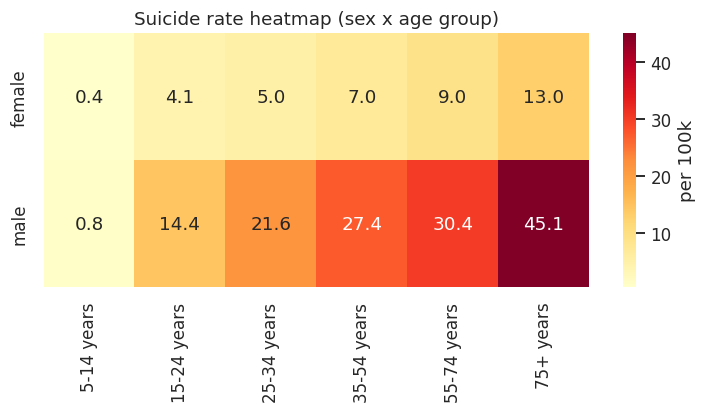

In [ ]:
hm = rate(df, ["sex", "age"])["rate"].unstack()
plt.figure(figsize=(8, 3))
sns.heatmap(hm, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "per 100k"})
plt.title("Suicide rate heatmap (sex x age group)"); plt.xlabel(""); plt.ylabel("")
plt.show()

### 4.7 Economy vs suicide rate (country level)

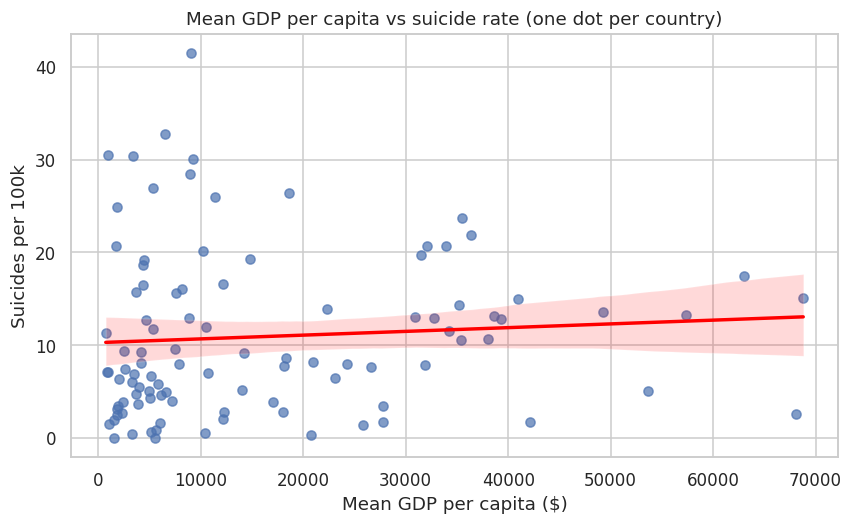

Pearson r = 0.08  (correlation, not causation)


In [ ]:
c = df.groupby("country", observed=True).agg(gdp_pc=("gdp_per_capita", "mean"),
                                             s=("suicides_no", "sum"), p=("population", "sum")).reset_index()
c["rate"] = c["s"] / c["p"] * 100_000
c = c[c["p"] > 0]

plt.figure(figsize=(9, 5))
sns.regplot(data=c, x="gdp_pc", y="rate", scatter_kws={"alpha": 0.7}, line_kws={"color": "red"})
plt.title("Mean GDP per capita vs suicide rate (one dot per country)")
plt.xlabel("Mean GDP per capita ($)"); plt.ylabel("Suicides per 100k")
plt.show()
r = c["gdp_pc"].corr(c["rate"])
print(f"Pearson r = {r:.2f}  (correlation, not causation)")

### 4.8 Correlation heatmap of numeric variables

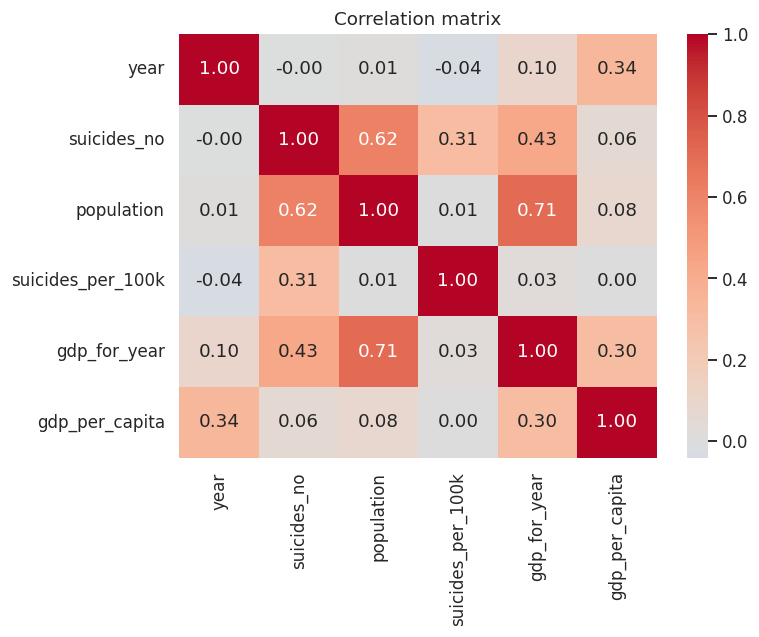

In [ ]:
num = df[["year", "suicides_no", "population", "suicides_per_100k", "gdp_for_year", "gdp_per_capita"]]
plt.figure(figsize=(7, 5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

## 5. Key numbers for the report

In [ ]:
overall = df["suicides_no"].sum() / df["population"].sum() * 100_000
s = rate(df, "sex")["rate"]
a = rate(df, "age")["rate"]
y = rate(df, "year")["rate"]
cr = rate(df, "country")["rate"].sort_values(ascending=False)

print(f"Overall pooled rate: {overall:.2f} per 100k")
print(f"Male / female rate ratio: {s['male'] / s['female']:.1f}x  (male {s['male']:.1f}, female {s['female']:.1f})")
print(f"Highest-risk age group: {a.idxmax()} ({a.max():.1f}); lowest: {a.idxmin()} ({a.min():.1f})")
print(f"Peak year: {y.idxmax()} ({y.max():.1f}); 2015: {y.loc[2015]:.1f}; change from peak: {(y.loc[2015]/y.max()-1)*100:.0f}%")
print("Top 5 countries:", ", ".join(f"{k} ({v:.1f})" for k, v in cr.head(5).items()))
print(f"GDP per capita vs rate (country level) r = {r:.2f}")

Overall pooled rate: 13.15 per 100k
Male / female rate ratio: 3.5x  (male 20.7, female 5.9)
Highest-risk age group: 75+ years (24.5); lowest: 5-14 years (0.6)
Peak year: 1995 (15.3); 2015: 11.5; change from peak: -25%
Top 5 countries: Lithuania (41.5), Russian Federation (32.8), Sri Lanka (30.5), Belarus (30.3), Hungary (30.0)
GDP per capita vs rate (country level) r = 0.08


## 6. Short insights report

**Data quality**
- `hdi_for_year` was ~70% missing, so the column was dropped instead of imputed.
- No duplicate rows were found; `gdp_for_year` was converted from text to numeric; `age`/`generation` were made ordered categoricals.
- 2016 was excluded because far fewer countries report that year, which would bias the trend.
- IQR outliers are concentrated in older male groups and a few countries; they are genuine values and were kept.

**What the visualizations show** *(confirm the exact numbers against the output of the cell above)*
1. **Time trend:** the global rate rose through the early/mid 1990s, peaked, and then declined gradually over the following two decades.
2. **Sex:** the male rate is several times higher than the female rate in every year, and the gap stays large over time.
3. **Age:** the rate rises with age; the 75+ and 55-74 groups have the highest rates, children (5-14) the lowest.
4. **Countries:** the highest rates are concentrated in Eastern Europe (e.g. Lithuania, Russian Federation) plus a few others (e.g. Sri Lanka, South Korea); the top-10 chart lists them.
5. **Generation:** older generations show higher pooled rates, but this largely reflects age (they are observed at older ages), so it should not be read as a generation effect.
6. **Economy:** the relationship between GDP per capita and suicide rate is weak at country level; wealth alone does not explain differences.

**Limitations**
- Data are reported counts; reporting quality and definitions vary by country and year.
- The dataset has no mental-health, social or policy variables, so these results describe patterns only, not causes.
- Country-level correlations may not hold for individuals (ecological fallacy).

**Conclusion:** sex and age are by far the strongest patterns in this data; economic level and year matter much less.